In [1]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
import random
import torch

In [2]:
# set seeds 
np.random.seed(10)
torch.manual_seed(1)
random.seed(10)

In [3]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [4]:
work_folder = 'trivia'
saving_folder = 'prova'
os.chdir(work_folder)

In [5]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../")))
from trivia_env import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))


In [6]:
file_path = saving_folder + '/' + 'parameters.txt'  # Path to the parameters file

parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

max_steps = 30
batch_size = 64
gamma = 0.99
max_size = 10000000
state_dim = (1, 3, 3)
action_dim = 8
action_bound = 1
actor_lr = 0.0001
critic_lr = 0.001
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.01
policy_steps = 30
learning_steps = 10


In [7]:
env = SimpleEnvCNN(max_steps)

In [8]:
from trivia_ppo import *
config_net_file = f"{saving_folder}/networks.yaml"
ppo_trivia = PPO_trivia(env,
                 gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                 clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                 state_dim, action_dim, clip_grad=False,
                 use_gae=True, lam=0.95)

In [9]:
ppo_trivia.setup_networks()

if not os.path.exists(saving_folder + '/results'):
    os.makedirs(saving_folder + '/results')

if not os.path.exists(saving_folder + '/results_test'):
    os.makedirs(saving_folder + '/results_test')

if not os.path.exists(saving_folder + '/weights'):
    os.makedirs(saving_folder + '/weights')

with open(saving_folder + '/results/results.txt', 'w') as file:
    file.write(f"")

with open(saving_folder + '/results/reward.txt', 'w') as file:
    file.write(f"")
    
'''with open(saving_folder + '/results/op.txt', 'w') as file:
    file.write(f"")'''
    
with open(saving_folder + '/results_test/reward.txt', 'w') as file:
    file.write(f"")

'''with open(saving_folder + '/results_test/op.txt', 'w') as file:
    file.write(f"")'''

with open(saving_folder + '/results/actor_weights.txt', 'w') as file:
    file.write(f"")

with open(saving_folder + '/results/critic_weights.txt', 'w') as file:
    file.write(f"")

In [10]:
print(ppo_trivia.critic)

CNN_critic(
  (cnn_layers): Sequential(
    (0): Conv2d(1, 32, kernel_size=(2, 2), stride=(1, 1), padding=valid)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
  )
  (fc_layers): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.0, inplace=False)
  )
  (output_layer): Linear(in_features=64, out_features=1, bias=True)
)


In [11]:
cw = ppo_trivia.compute_critic_weights()
indx_w_critic = []

for i in range(len(cw)):
    try:
        cw[i].numpy().shape[1]
        indx_w_critic.append(i)
    except:
        pass

aw = ppo_trivia.compute_actor_weights()
indx_w_actor = []

for i in range(len(aw)):
    try:
        aw[i].numpy().shape[1]
        indx_w_actor.append(i)
    except:
        pass

In [12]:
epi = 0

In [13]:
ppo_trivia.get_state().shape

(10, 1, 3, 3)

In [14]:
a = ppo_trivia.policy(ppo_trivia.get_state())

In [15]:
a.shape

(10,)

In [16]:
env.directions[a]

array([[ 0, -1],
       [ 0, -1],
       [-1, -1],
       [ 0,  1],
       [ 0, -1],
       [ 0,  1],
       [-1, -1],
       [ 0,  1],
       [ 1,  1],
       [-1,  1]])

In [17]:
s,r,d = ppo_trivia.execute_action(a)

In [18]:
while epi < 100:
        
    score, act = ppo_trivia.training_episode()

    if epi %1 == 0:
        
        if epi %10 == 0:
                
            score_test, act_test = ppo_trivia.test_episode()
                
            with open(saving_folder + '/results/reward.txt', 'a') as file:
                for item in score:
                    file.write(f"{item}\n")

            with open(saving_folder + '/results_test/reward.txt', 'a') as file:
                for item in score_test:
                    file.write(f"{np.mean(item)}\n")

        cw = ppo_trivia.compute_critic_weights()
        aw = ppo_trivia.compute_actor_weights()

        with open(saving_folder + '/results/critic_weights.txt', 'a') as f:
            f.write(str([cw[i].numpy().sum() for i in indx_w_critic]) + '\n')

        with open(saving_folder + '/results/actor_weights.txt', 'a') as f:
            f.write(str([aw[i].numpy().sum() for i in indx_w_actor]) + '\n')

        ppo_trivia.save_weights(saving_folder + '/weights')

    avg_score = np.mean(score)
    avg_a = np.mean(act)
    
    with open(saving_folder + '/results/results.txt', 'a') as f:
                    
        f.write(str(epi) + ' '  + str(avg_score) + ' ' + str(avg_a) + '\n')

    epi += 1 
    
    print('epi: ', epi, ' score: ', np.sum(score), end='\r')

KeyboardInterrupt: 

In [19]:
results = ppo_trivia.test_episode()

In [20]:
rew = np.array(results[0])
act = np.array(results[1])

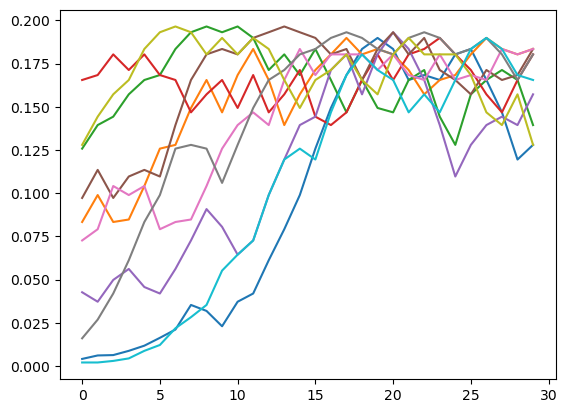

In [21]:
plt.plot(rew)

In [22]:
print(ppo_trivia.critic.state_dict().keys())

odict_keys(['cnn_layers.0.weight', 'cnn_layers.0.bias', 'cnn_layers.1.weight', 'cnn_layers.1.bias', 'cnn_layers.1.running_mean', 'cnn_layers.1.running_var', 'cnn_layers.1.num_batches_tracked', 'fc_layers.0.weight', 'fc_layers.0.bias', 'fc_layers.1.weight', 'fc_layers.1.bias', 'fc_layers.1.running_mean', 'fc_layers.1.running_var', 'fc_layers.1.num_batches_tracked', 'fc_layers.4.weight', 'fc_layers.4.bias', 'fc_layers.5.weight', 'fc_layers.5.bias', 'fc_layers.5.running_mean', 'fc_layers.5.running_var', 'fc_layers.5.num_batches_tracked', 'output_layer.weight', 'output_layer.bias'])


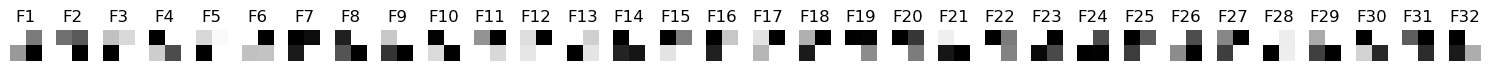

In [23]:
# plot the learned filters 
# odict_keys(['cnn_layers.0.weight', 'cnn_layers.0.bias', 'cnn_layers.1.weight', 'cnn_layers.1.bias', 'cnn_layers.1.running_mean', 'cnn_layers.1.running_var', 'cnn_layers.1.num_batches_tracked', 'fc_layers.0.weight', 'fc_layers.0.bias', 'fc_layers.1.weight', 'fc_layers.1.bias', 'fc_layers.1.running_mean', 'fc_layers.1.running_var', 'fc_layers.1.num_batches_tracked', 'fc_layers.4.weight', 'fc_layers.4.bias', 'fc_layers.5.weight', 'fc_layers.5.bias', 'fc_layers.5.running_mean', 'fc_layers.5.running_var', 'fc_layers.5.num_batches_tracked', 'output_layer.weight', 'output_layer.bias'])
plt.figure(figsize=(15, 5))
for i in range(ppo_trivia.critic.cnn_layers[0].weight.shape[0]):
    plt.subplot(1, ppo_trivia.critic.cnn_layers[0].weight.shape[0], i + 1)
    plt.imshow(ppo_trivia.critic.cnn_layers[0].weight.data.cpu().numpy()[i, 0, :, :], cmap='gray')
    plt.axis('off')
    plt.title(f'F{i+1}')
plt.tight_layout()

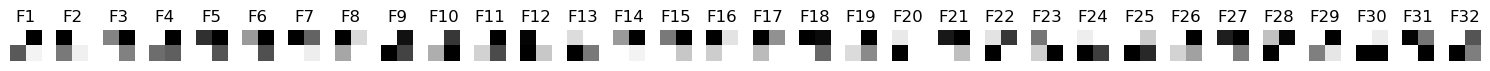

In [24]:
plt.figure(figsize=(15, 5))
for i in range(ppo_trivia.actor.cnn_layers[0].weight.shape[0]):
    plt.subplot(1, ppo_trivia.actor.cnn_layers[0].weight.shape[0], i + 1)
    plt.imshow(ppo_trivia.actor.cnn_layers[0].weight.data.cpu().numpy()[i, 0, :, :], cmap='gray')
    plt.axis('off')
    plt.title(f'F{i+1}')
plt.tight_layout()